In [17]:
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from tqdm import tqdm

In [11]:
def plot_tail_kld_experiment(
    experiment_name,
    kld_type="kld_any",
    conf_percentiles=(5, 95),
    ylim=None,
    figsize=(8, 5),
    ax=None,
    legend=True,
    title=True,
    max_threshold=None,
    log_scale_y=False,           # <--- new: put y axis on log scale
):
    # ── Load all finished runs for this experiment ────────────────────────────
    experiment = mlflow.get_experiment_by_name(experiment_name)
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found.")

    df_runs = mlflow.search_runs([experiment.experiment_id])
    df_runs = df_runs[df_runs["status"] == "FINISHED"].reset_index(drop=True)

    # ── Split runs into the 4 groups by run name ──────────────────────────────
    def _run_name(row):
        return row["tags.mlflow.runName"]

    def _is_no(row):
        name = _run_name(row)
        return ("No" in name) and ("Bootstrap" not in name) and ("Lasso" not in name)

    def _is_lasso(row):
        name = _run_name(row)
        return ("Lasso" in name) and ("Adaptive" not in name) and ("Bootstrap" not in name)

    def _is_adaptive(row):
        name = _run_name(row)
        return ("Adaptive" in name) and ("Bootstrap" not in name)

    idx_no       = [_is_no(df_runs.iloc[i])       for i in range(len(df_runs))]
    idx_lasso    = [_is_lasso(df_runs.iloc[i])    for i in range(len(df_runs))]
    idx_adaptive = [_is_adaptive(df_runs.iloc[i]) for i in range(len(df_runs))]

    df_no       = df_runs[idx_no].reset_index(drop=True)
    df_lasso    = df_runs[idx_lasso].reset_index(drop=True)
    df_adaptive = df_runs[idx_adaptive].reset_index(drop=True)

    print(f"  Runs found — No: {len(df_no)} | Lasso: {len(df_lasso)} | Adaptive: {len(df_adaptive)}")

    # ── Helper: load tail kld tables ──────────────────────────────────────────
    def load_tail_kld_tables(df_subset, artifact_name):
        tables = []
        for _, row in df_subset.iterrows():
            try:
                path = mlflow.artifacts.download_artifacts(
                    run_id        = row["run_id"],
                    artifact_path = artifact_name,
                )
                df = pd.read_csv(path)
                if max_threshold is not None:
                    df = df[df["threshold"] <= max_threshold].reset_index(drop=True)
                tables.append(df)
            except Exception as e:
                print(f"    WARNING: could not load {artifact_name} for run "
                      f"{row['tags.mlflow.runName']}: {e}")
        return tables

    tables_no       = load_tail_kld_tables(df_no,       "gtm_tail_kld_table.csv")
    tables_lasso    = load_tail_kld_tables(df_lasso,    "gtm_tail_kld_table.csv")
    tables_adaptive = load_tail_kld_tables(df_adaptive, "gtm_tail_kld_table.csv")
    tables_ggm      = load_tail_kld_tables(df_no,       "ggm_tail_kld_table.csv")

    # ── Helper: stack tables and compute mean + CI ────────────────────────────
    def compute_stats_from_tables(tables, kld_col):
        if len(tables) == 0:
            return None, None, None, None

        stacked    = np.stack([df[kld_col].values for df in tables], axis=0)
        thresholds = tables[0]["threshold"].values

        mean  = np.nanmean(stacked,                             axis=0)
        lower = np.nanpercentile(stacked, conf_percentiles[0], axis=0)
        upper = np.nanpercentile(stacked, conf_percentiles[1], axis=0)

        return thresholds, mean, lower, upper

    thresh_no,       mean_no,       lower_no,       upper_no       = compute_stats_from_tables(tables_no,       kld_type)
    thresh_lasso,    mean_lasso,    lower_lasso,    upper_lasso    = compute_stats_from_tables(tables_lasso,    kld_type)
    thresh_adaptive, mean_adaptive, lower_adaptive, upper_adaptive = compute_stats_from_tables(tables_adaptive, kld_type)
    thresh_ggm,      mean_ggm,      lower_ggm,      upper_ggm      = compute_stats_from_tables(tables_ggm,      kld_type)

    # ── Plot ──────────────────────────────────────────────────────────────────
    colors = {
        "no"       : "#1f77b4",
        "lasso"    : "#ff7f0e",
        "adaptive" : "#2ca02c",
        "ggm"      : "#d62728",
    }

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    def _plot_line(ax, thresholds, mean, lower, upper, color, label):
        if thresholds is None:
            return
        ax.plot(thresholds, mean, color=color, label=label, linewidth=1.5)
        ax.fill_between(thresholds, lower, upper, color=color, alpha=0.15)

    _plot_line(ax, thresh_no,       mean_no,       lower_no,       upper_no,       colors["no"],       "No Lasso")
    _plot_line(ax, thresh_lasso,    mean_lasso,    lower_lasso,    upper_lasso,    colors["lasso"],    "Lasso")
    _plot_line(ax, thresh_adaptive, mean_adaptive, lower_adaptive, upper_adaptive, colors["adaptive"], "Adaptive Lasso")
    _plot_line(ax, thresh_ggm,      mean_ggm,      lower_ggm,      upper_ggm,      colors["ggm"],      "GGM")

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Abs Value Threshold")
    ax.set_ylabel(f"KLD ({kld_type})")
    ax.grid(True, linestyle="--", linewidth=0.4)

    # ── Log scale ─────────────────────────────────────────────────────────────
    # Note: log scale requires positive values — KLD can be negative at low
    # thresholds (model better than true in that region) so we clip to a small
    # positive floor before setting the scale to avoid blank/broken plots.
    # ylim should be set accordingly e.g. ylim=(1e-3, 10)
    if log_scale_y:
        ax.set_yscale("log")

    if title:
        ax.set_title(
            f"{experiment_name}\n"
            f"Tail KLD — {kld_type} | "
            f"CI: [{conf_percentiles[0]}%, {conf_percentiles[1]}%]"
            + (" | log scale" if log_scale_y else "")
        )
    if legend:
        ax.legend()
    if ylim is not None:
        ax.set_ylim(ylim)

  Runs found — No: 100 | Lasso: 100 | Adaptive: 100
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_58271/1868499099.py:78: RuntimeWarning: Mean of empty slice
  mean  = np.nanmean(stacked,                             axis=0)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


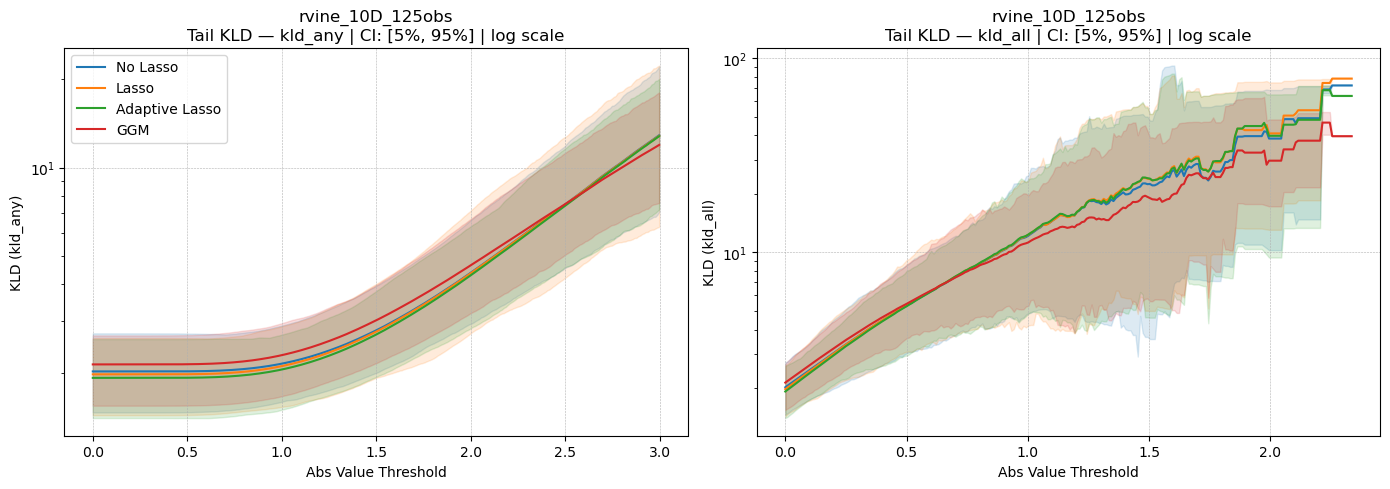

In [12]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_tail_kld_experiment(
    experiment_name  = "rvine_10D_125obs",
    kld_type         = "kld_any",
    conf_percentiles = (5, 95),
    ax               = axes[0],
    legend           = True,
    title            = True,
    max_threshold    = 3,
    log_scale_y      = True
)

plot_tail_kld_experiment(
    experiment_name  = "rvine_10D_125obs",
    kld_type         = "kld_all",
    conf_percentiles = (5, 95),
    ax               = axes[1],
    legend           = False,
    title            = True,
    max_threshold    = 3,
    log_scale_y      = True
)

plt.tight_layout()
plt.show()

  Runs found — No: 100 | Lasso: 100 | Adaptive: 100
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_58271/1868499099.py:78: RuntimeWarning: Mean of empty slice
  mean  = np.nanmean(stacked,                             axis=0)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


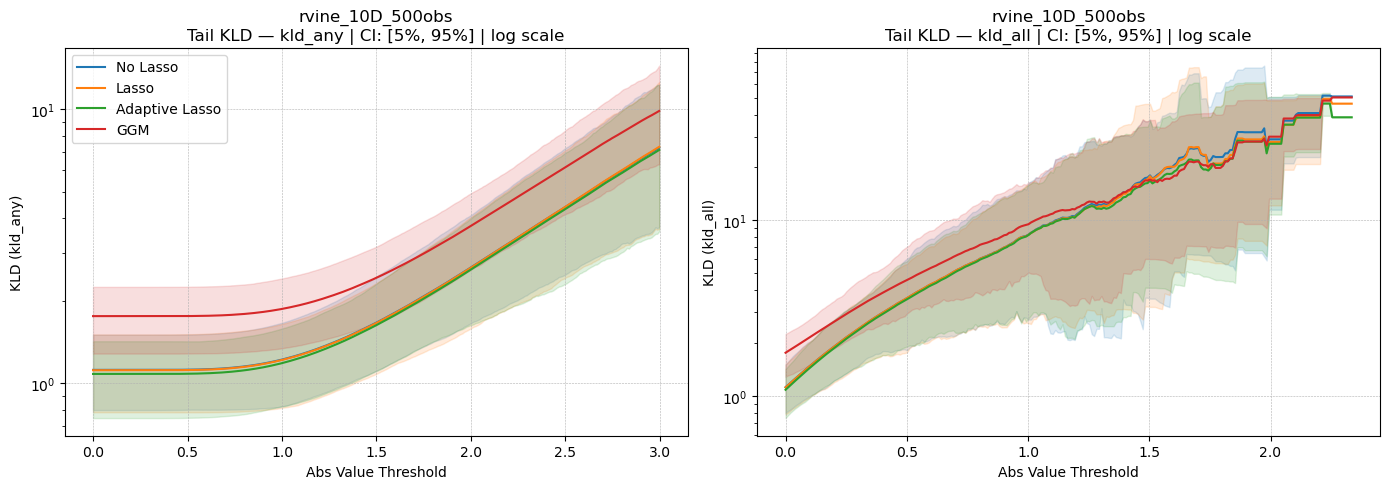

In [14]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_tail_kld_experiment(
    experiment_name  = "rvine_10D_500obs",
    kld_type         = "kld_any",
    conf_percentiles = (5, 95),
    ax               = axes[0],
    legend           = True,
    title            = True,
    max_threshold    = 3,
    log_scale_y      = True
)

plot_tail_kld_experiment(
    experiment_name  = "rvine_10D_500obs",
    kld_type         = "kld_all",
    conf_percentiles = (5, 95),
    ax               = axes[1],
    legend           = False,
    title            = True,
    max_threshold    = 3,
    log_scale_y      = True
)

plt.tight_layout()
plt.show()

  Runs found — No: 100 | Lasso: 100 | Adaptive: 100
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_58271/1868499099.py:78: RuntimeWarning: Mean of empty slice
  mean  = np.nanmean(stacked,                             axis=0)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


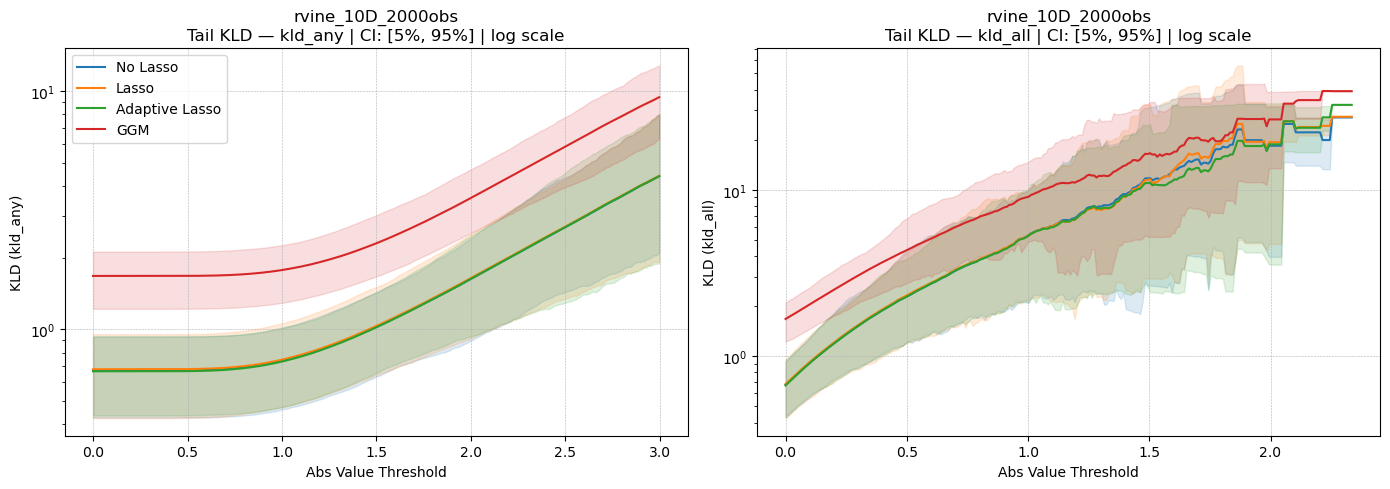

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_tail_kld_experiment(
    experiment_name  = "rvine_10D_2000obs",
    kld_type         = "kld_any",
    conf_percentiles = (5, 95),
    ax               = axes[0],
    legend           = True,
    title            = True,
    max_threshold    = 3,
    log_scale_y      = True
)

plot_tail_kld_experiment(
    experiment_name  = "rvine_10D_2000obs",
    kld_type         = "kld_all",
    conf_percentiles = (5, 95),
    ax               = axes[1],
    legend           = False,
    title            = True,
    max_threshold    = 3,
    log_scale_y      = True
)

plt.tight_layout()
plt.show()

In [23]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_names = [
    # cvine normal
    "cvine_10D_125obs", "cvine_10D_500obs", "cvine_10D_2000obs",
    # cvine strong
    "cvine_strong_10D_125obs", "cvine_strong_10D_500obs", "cvine_strong_10D_2000obs",
    # dvine normal
    "dvine_10D_125obs", "dvine_10D_500obs", "dvine_10D_2000obs",
    # dvine strong
    "dvine_strong_10D_125obs", "dvine_strong_10D_500obs", "dvine_strong_10D_2000obs",
    # rvine normal
    "rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs",
    # rvine strong
    "rvine_strong_10D_125obs", "rvine_strong_10D_500obs", "rvine_strong_10D_2000obs",
]


kld_types        = ["kld_any", "kld_all"]
scale_types      = ["linear", "log"]
max_threshold    = 2.5
conf_percentiles = (5, 95)

# y axis limits per scale type — both start at 0
ylim_config = {
    "linear" : (None, None),    # 0 min, auto upper
    "log"    : (None, None),   # log scale needs positive floor, not 0
}

pbar = tqdm(experiment_names, desc="Experiments")

for experiment_name in pbar:

    pbar.set_description(f"Experiment: {experiment_name}")

    show_legend = experiment_name.startswith("rvine")

    try:
        for kld_type in kld_types:
            for scale_type in scale_types:

                fig, ax = plt.subplots(figsize=(7, 5))

                plot_tail_kld_experiment(
                    experiment_name  = experiment_name,
                    kld_type         = kld_type,
                    conf_percentiles = conf_percentiles,
                    max_threshold    = max_threshold,
                    log_scale_y      = (scale_type == "log"),
                    ylim             = ylim_config[scale_type],
                    ax               = ax,
                    legend           = show_legend,
                    title            = False,
                )

                # e.g. tail_kld_linear_kld_any_rvine_10D_125obs.png
                filename = f"tail_kld_{scale_type}_{kld_type}_{experiment_name}.png"
                plt.tight_layout()
                plt.savefig(filename, dpi=150)
                plt.close(fig)
                tqdm.write(f"  Saved: {filename}")

    except Exception as e:
        tqdm.write(f"  FAILED: {experiment_name} | Reason: {e}")
        plt.close("all")
        continue

tqdm.write("\nAll done.")

Experiment: cvine_10D_125obs:   0%|          | 0/18 [00:00<?, ?it/s]

  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


Experiment: cvine_10D_125obs:   0%|          | 0/18 [00:10<?, ?it/s]

  Saved: tail_kld_linear_kld_any_cvine_10D_125obs.png
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


Experiment: cvine_10D_125obs:   0%|          | 0/18 [00:19<?, ?it/s]

  Saved: tail_kld_log_kld_any_cvine_10D_125obs.png
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


... (136 outputs left out)

Experiment: rvine_strong_10D_2000obs:  94%|█████████▍| 17/18 [09:50<00:30, 30.15s/it]

  Saved: tail_kld_linear_kld_all_rvine_strong_10D_2000obs.png
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


Experiment: rvine_strong_10D_2000obs: 100%|██████████| 18/18 [09:59<00:00, 33.28s/it]

  Saved: tail_kld_log_kld_all_rvine_strong_10D_2000obs.png

All done.


In [24]:
def plot_tail_kld_experiment(
    experiment_name,
    kld_type="kld_any",
    conf_percentiles=(5, 95),
    ylim=None,
    figsize=(8, 5),
    ax=None,
    legend=True,
    title=True,
    max_threshold=None,
    log_scale_y=False,
    extra_experiments=None,   # <--- new: dict of {label: (experiment_name, artifact_name, color)}
):
    """
    extra_experiments allows adding arbitrary extra lines from other experiments.

    Example:
        extra_experiments = {
            "MAF": ("maf_rvine_10D_125obs", "nf_tail_kld_table.csv", "#9467bd"),
            "SNF": ("snf_rvine_10D_125obs", "nf_tail_kld_table.csv", "#8c564b"),
        }
    """

    # ── Load all finished runs for this experiment ────────────────────────────
    experiment = mlflow.get_experiment_by_name(experiment_name)
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found.")

    df_runs = mlflow.search_runs([experiment.experiment_id])
    df_runs = df_runs[df_runs["status"] == "FINISHED"].reset_index(drop=True)

    # ── Split runs into the 4 groups by run name ──────────────────────────────
    def _run_name(row):
        return row["tags.mlflow.runName"]

    def _is_no(row):
        name = _run_name(row)
        return ("No" in name) and ("Bootstrap" not in name) and ("Lasso" not in name)

    def _is_lasso(row):
        name = _run_name(row)
        return ("Lasso" in name) and ("Adaptive" not in name) and ("Bootstrap" not in name)

    def _is_adaptive(row):
        name = _run_name(row)
        return ("Adaptive" in name) and ("Bootstrap" not in name)

    idx_no       = [_is_no(df_runs.iloc[i])       for i in range(len(df_runs))]
    idx_lasso    = [_is_lasso(df_runs.iloc[i])    for i in range(len(df_runs))]
    idx_adaptive = [_is_adaptive(df_runs.iloc[i]) for i in range(len(df_runs))]

    df_no       = df_runs[idx_no].reset_index(drop=True)
    df_lasso    = df_runs[idx_lasso].reset_index(drop=True)
    df_adaptive = df_runs[idx_adaptive].reset_index(drop=True)

    print(f"  Runs found — No: {len(df_no)} | Lasso: {len(df_lasso)} | Adaptive: {len(df_adaptive)}")

    # ── Helper: load tail kld tables ──────────────────────────────────────────
    def load_tail_kld_tables(df_subset, artifact_name):
        tables = []
        for _, row in df_subset.iterrows():
            try:
                path = mlflow.artifacts.download_artifacts(
                    run_id        = row["run_id"],
                    artifact_path = artifact_name,
                )
                df = pd.read_csv(path)
                if max_threshold is not None:
                    df = df[df["threshold"] <= max_threshold].reset_index(drop=True)
                tables.append(df)
            except Exception as e:
                print(f"    WARNING: could not load {artifact_name} for run "
                      f"{row['tags.mlflow.runName']}: {e}")
        return tables

    # ── Helper: load tables from a separate experiment by name ────────────────
    def load_tail_kld_tables_from_experiment(extra_experiment_name, artifact_name):
        """
        Loads artifact_name from all finished runs of extra_experiment_name.
        Used for MAF, SNF etc. which live in separate mlflow experiments.
        """
        exp = mlflow.get_experiment_by_name(extra_experiment_name)
        if exp is None:
            print(f"    WARNING: extra experiment '{extra_experiment_name}' not found.")
            return []
        df_extra = mlflow.search_runs([exp.experiment_id])
        df_extra = df_extra[df_extra["status"] == "FINISHED"].reset_index(drop=True)
        return load_tail_kld_tables(df_extra, artifact_name)

    # ── Load main experiment tables ───────────────────────────────────────────
    tables_no       = load_tail_kld_tables(df_no,       "gtm_tail_kld_table.csv")
    tables_lasso    = load_tail_kld_tables(df_lasso,    "gtm_tail_kld_table.csv")
    tables_adaptive = load_tail_kld_tables(df_adaptive, "gtm_tail_kld_table.csv")
    tables_ggm      = load_tail_kld_tables(df_no,       "ggm_tail_kld_table.csv")

    # ── Load extra experiment tables ──────────────────────────────────────────
    extra_tables = {}
    if extra_experiments is not None:
        for label, (extra_exp_name, artifact_name, color) in extra_experiments.items():
            extra_tables[label] = (
                load_tail_kld_tables_from_experiment(extra_exp_name, artifact_name),
                color,
            )

    # ── Helper: stack tables and compute mean + CI ────────────────────────────
    def compute_stats_from_tables(tables, kld_col):
        if len(tables) == 0:
            return None, None, None, None
        stacked    = np.stack([df[kld_col].values for df in tables], axis=0)
        thresholds = tables[0]["threshold"].values
        mean  = np.nanmean(stacked,                             axis=0)
        lower = np.nanpercentile(stacked, conf_percentiles[0], axis=0)
        upper = np.nanpercentile(stacked, conf_percentiles[1], axis=0)
        return thresholds, mean, lower, upper

    thresh_no,       mean_no,       lower_no,       upper_no       = compute_stats_from_tables(tables_no,       kld_type)
    thresh_lasso,    mean_lasso,    lower_lasso,    upper_lasso    = compute_stats_from_tables(tables_lasso,    kld_type)
    thresh_adaptive, mean_adaptive, lower_adaptive, upper_adaptive = compute_stats_from_tables(tables_adaptive, kld_type)
    thresh_ggm,      mean_ggm,      lower_ggm,      upper_ggm      = compute_stats_from_tables(tables_ggm,      kld_type)

    # ── Plot ──────────────────────────────────────────────────────────────────
    colors = {
        "no"       : "#1f77b4",
        "lasso"    : "#ff7f0e",
        "adaptive" : "#2ca02c",
        "ggm"      : "#d62728",
    }

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    def _plot_line(ax, thresholds, mean, lower, upper, color, label):
        if thresholds is None:
            return
        ax.plot(thresholds, mean, color=color, label=label, linewidth=1.5)
        ax.fill_between(thresholds, lower, upper, color=color, alpha=0.15)

    # Main lines
    _plot_line(ax, thresh_no,       mean_no,       lower_no,       upper_no,       colors["no"],       "No Lasso")
    _plot_line(ax, thresh_lasso,    mean_lasso,    lower_lasso,    upper_lasso,    colors["lasso"],    "Lasso")
    _plot_line(ax, thresh_adaptive, mean_adaptive, lower_adaptive, upper_adaptive, colors["adaptive"], "Adaptive Lasso")
    _plot_line(ax, thresh_ggm,      mean_ggm,      lower_ggm,      upper_ggm,      colors["ggm"],      "GGM")

    # Extra lines (MAF, SNF, ...)
    for label, (tables, color) in extra_tables.items():
        thresh_extra, mean_extra, lower_extra, upper_extra = compute_stats_from_tables(tables, kld_type)
        _plot_line(ax, thresh_extra, mean_extra, lower_extra, upper_extra, color, label)

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Abs Value Threshold")
    ax.set_ylabel(f"KLD ({kld_type})")
    ax.grid(True, linestyle="--", linewidth=0.4)

    if log_scale_y:
        ax.set_yscale("log")
    if title:
        ax.set_title(
            f"{experiment_name}\n"
            f"Tail KLD — {kld_type} | "
            f"CI: [{conf_percentiles[0]}%, {conf_percentiles[1]}%]"
            + (" | log scale" if log_scale_y else "")
        )
    if legend:
        ax.legend()
    if ylim is not None:
        ax.set_ylim(ylim)

In [26]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_names = [
    #"cvine_10D_125obs", "cvine_10D_500obs", "cvine_10D_2000obs",
    #"cvine_strong_10D_125obs", "cvine_strong_10D_500obs", "cvine_strong_10D_2000obs",
    #"dvine_10D_125obs", "dvine_10D_500obs", "dvine_10D_2000obs",
    #"dvine_strong_10D_125obs", "dvine_strong_10D_500obs", "dvine_strong_10D_2000obs",
    "rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs",
    #"rvine_strong_10D_125obs", "rvine_strong_10D_500obs", "rvine_strong_10D_2000obs",
]

# rvine normal experiments that get MAF and SNF extra lines
rvine_normal_experiments = {
    "rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs"
}

kld_types        = ["kld_any", "kld_all"]
scale_types      = ["linear", "log"]
max_threshold    = 2.5
conf_percentiles = (5, 95)

ylim_config = {
    "linear" : (None, None),
    "log"    : (None, None),
}

pbar = tqdm(experiment_names, desc="Experiments")

for experiment_name in pbar:

    pbar.set_description(f"Experiment: {experiment_name}")

    show_legend = experiment_name.startswith("rvine")

    # Build extra_experiments dict for rvine normal runs only
    if experiment_name in rvine_normal_experiments:
        # Extract obs string e.g. "125obs" from "rvine_10D_125obs"
        obs_str = experiment_name.split("_")[-1]   # e.g. "125obs"
        extra_experiments = {
            "MAF": (f"maf_rvine_10D_{obs_str}", "nf_tail_kld_table.csv", "#9467bd"),
            "SNF": (f"snf_rvine_10D_{obs_str}", "nf_tail_kld_table.csv", "#8c564b"),
        }
    else:
        extra_experiments = None

    try:
        for kld_type in kld_types:
            for scale_type in scale_types:

                fig, ax = plt.subplots(figsize=(7, 5))

                plot_tail_kld_experiment(
                    experiment_name   = experiment_name,
                    kld_type          = kld_type,
                    conf_percentiles  = conf_percentiles,
                    max_threshold     = max_threshold,
                    log_scale_y       = (scale_type == "log"),
                    ylim              = ylim_config[scale_type],
                    ax                = ax,
                    legend            = show_legend,
                    title             = False,
                    extra_experiments = extra_experiments,
                )

                filename = f"tail_kld_{scale_type}_{kld_type}_{experiment_name}.png"
                plt.tight_layout()
                plt.savefig(filename, dpi=150)
                plt.close(fig)
                tqdm.write(f"  Saved: {filename}")

    except Exception as e:
        tqdm.write(f"  FAILED: {experiment_name} | Reason: {e}")
        plt.close("all")
        continue

tqdm.write("\nAll done.")

Experiment: rvine_10D_125obs:   0%|          | 0/3 [00:00<?, ?it/s]

  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


Experiment: rvine_10D_125obs:   0%|          | 0/3 [00:13<?, ?it/s]

  Saved: tail_kld_linear_kld_any_rvine_10D_125obs.png
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


Experiment: rvine_10D_125obs:   0%|          | 0/3 [00:24<?, ?it/s]

  Saved: tail_kld_log_kld_any_rvine_10D_125obs.png
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


... (16 outputs left out)

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_58271/645345462.py:111: RuntimeWarning: Mean of empty slice
  mean  = np.nanmean(stacked,                             axis=0)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
Experiment: rvine_10D_2000obs:  67%|██████▋   | 2/3 [02:16<00:51, 51.25s/it]

  Saved: tail_kld_linear_kld_all_rvine_10D_2000obs.png
  Runs found — No: 100 | Lasso: 100 | Adaptive: 100


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_58271/645345462.py:111: RuntimeWarning: Mean of empty slice
  mean  = np.nanmean(stacked,                             axis=0)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
Experiment: rvine_10D_2000obs: 100%|██████████| 3/3 [02:28<00:00, 49.49s/it]

  Saved: tail_kld_log_kld_all_rvine_10D_2000obs.png

All done.
